# Atividade de Extensão — Mini-Projeto: Motor CC
## Um novo motor para vocês calibrarem e simularem

Como na aula gravada, **o código não é fornecido** — apenas o enunciado e a validação ao
final de cada etapa. A estrutura é a mesma dos 3 atos do mini-projeto: calibração elétrica,
calibração mecânica e simulação dinâmica — mas agora para um motor CC diferente, ensaiado em
bancada com outros parâmetros.

### O modelo (o mesmo da aula)

$$L\frac{di}{dt} = V - R\,i - K_e\,\omega \qquad J\frac{d\omega}{dt} = K_t\,i - B\,\omega - T_{carga}$$

Estado $Y = [i, \omega]$, com $K_t = K_e$ (motor CC ideal, unidades SI).

### Dados do motor (datasheet)

```
L = 0.2 H     (indutância do enrolamento)
J = 0.015 kg.m^2   (momento de inércia do rotor)
V_nom = 36 V   (tensão nominal de alimentação)
```

| Etapa | Conteúdo | Peso |
|---|---|---|
| 1 | Calibração de R e Ke (mínimos quadrados) | Núcleo |
| 2 | Calibração de B (Vandermonde) | Núcleo |
| 3 | Simulação da partida (RK4) | Núcleo |
| 4 | Resposta a um degrau de carga | Aprofundamento (opcional) |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

L = 0.2
J = 0.015
V_nom = 36.0

---
## Etapa 1 (Núcleo) — Calibrando R e Ke

Pontos de operação medidos em bancada, em regime permanente (diferentes tensões e cargas
aplicadas). Em regime permanente, $V = R\,i + K_e\,\omega$.

## Roteiro

1. Monte a matriz $A = [i \;\; \omega]$ (cada linha um ponto de operação).
2. Resolva o sistema de mínimos quadrados pelas equações normais
   ($\text{coef} = (A^TA)^{-1}A^T V$), como visto em aula.
3. Guarde os resultados em `R_est` e `Ke_est`.

In [2]:
# Etapa 1 — Resolução
import numpy as np

V_pontos = np.array([18.0, 24.0, 30.0, 36.0, 36.0, 36.0])
I_pontos = np.array([1.662, 2.2333, 2.7823, 3.3215, 3.7153, 4.0527])
omega_pontos = np.array([80.896, 106.159, 134.82, 160.337, 145.205, 130.798])

import scipy.linalg

A = np.column_stack([I_pontos, omega_pontos])
coef, *_ = scipy.linalg.lstsq(A, V_pontos)   # biblioteca (scipy)
R_est, Ke_est = coef

In [3]:
# Validação — Etapa 1 (não modifique esta célula)
import numpy as np

assert "R_est" in dir() and "Ke_est" in dir(), "Defina R_est e Ke_est"
assert np.isclose(R_est, 4.9905, atol=0.05), f"R_est deveria ser aproximadamente 4.99 (encontrado {R_est:.4f})"
assert np.isclose(Ke_est, 0.1205, atol=0.01), f"Ke_est deveria ser aproximadamente 0.1205 (encontrado {Ke_est:.4f})"

print("Etapa 1 OK!")
print(f"  R_est = {R_est:.4f} Ω")
print(f"  Ke_est = {Ke_est:.4f} V.s/rad")

Etapa 1 OK!
  R_est = 4.9905 Ω
  Ke_est = 0.1205 V.s/rad


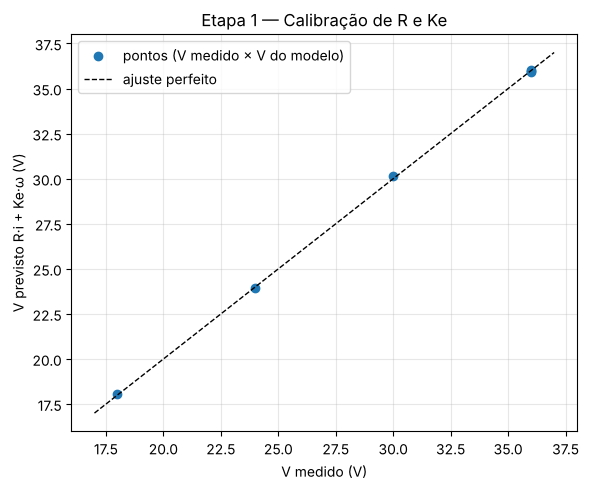

In [4]:
# Gráfico — Etapa 1: ajuste V = R·i + Ke·ω
V_modelo = A @ np.array([R_est, Ke_est])
plt.figure(figsize=(6, 5))
plt.plot(V_pontos, V_modelo, "o", label="pontos (V medido × V do modelo)")
lim = [V_pontos.min() - 1, V_pontos.max() + 1]
plt.plot(lim, lim, "k--", lw=1, label="ajuste perfeito")
plt.xlabel("V medido (V)")
plt.ylabel("V previsto R·i + Ke·ω (V)")
plt.title("Etapa 1 — Calibração de R e Ke")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

---
## Etapa 2 (Núcleo) — Calibrando o Atrito Viscoso (B)

Um segundo ensaio: o motor é girado externamente em diferentes velocidades e o torque de
atrito é medido. $T_{atrito} \approx B\,\omega$.

## Roteiro

1. Ajuste um polinômio de grau 1 a `T_atrito_medido` em função de `omega_teste` (Vandermonde,
   manual ou `np.polyfit` — à sua escolha).
2. Guarde a **inclinação** desse ajuste em `B_est` (o intercepto é ruído de medição — pode
   ser descartado).

In [5]:
# Etapa 2 — Resolução
omega_teste = np.array([40.0, 80.0, 120.0, 160.0, 200.0, 240.0])
T_atrito_medido = np.array([0.12237, 0.19042, 0.29334, 0.39348, 0.53309, 0.6328])


coef_B = np.polyfit(omega_teste, T_atrito_medido, 1)   # biblioteca (numpy): [inclinação, intercepto]
B_est = coef_B[0]

In [6]:
# Validação — Etapa 2 (não modifique esta célula)
import numpy as np

assert "B_est" in dir(), "Defina B_est"
assert np.isclose(B_est, 0.002629, atol=0.0003), f"B_est deveria ser aproximadamente 0.00263 (encontrado {B_est:.6f})"

print("Etapa 2 OK!")
print(f"  B_est = {B_est:.6f} N.m.s/rad")

Etapa 2 OK!
  B_est = 0.002629 N.m.s/rad


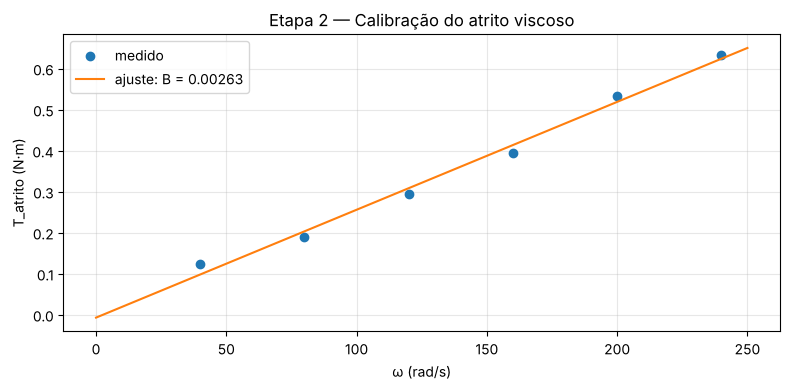

In [7]:
# Gráfico — Etapa 2: ajuste linear do atrito
w_fit = np.linspace(0, 250, 100)
plt.figure(figsize=(8, 4))
plt.plot(omega_teste, T_atrito_medido, "o", label="medido")
plt.plot(w_fit, np.polyval(coef_B, w_fit), "-", label=f"ajuste: B = {B_est:.5f}")
plt.xlabel("ω (rad/s)")
plt.ylabel("T_atrito (N·m)")
plt.title("Etapa 2 — Calibração do atrito viscoso")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

---
## Etapa 3 (Núcleo) — Simulando a Partida do Motor

Com $R$, $K_e$ e $B$ calibrados (e $K_t = K_e$), simule a partida do motor a partir do
repouso.

## Roteiro

1. Implemente (ou reaproveite) `rk4_sistema(F, t0, Y0, h, n_passos, **kwargs)` — mesmo
   formato do Módulo 3.
2. Defina `F_motor(t, Y, Vt, Tl)` a partir das equações do modelo.
3. Resolva com $V = V_{nom}$, $T_{carga}=0$, $Y_0=[0,0]$, $h=0.002$ s, até $t=16$ s. Guarde
   em `ts3` e `Ys3`.
4. Encontre o **pico de corrente** (`pico_corrente`) e o instante em que ele ocorre
   (`t_pico`).
5. Calcule a velocidade teórica de regime permanente
   $\omega_{ss} = \dfrac{K_t V_{nom}/R - T_{carga}}{B + K_tK_e/R}$ (guarde em
   `omega_ss_teorico`) e encontre o instante em que a simulação atinge 95% desse valor
   (guarde em `tempo_95`).

In [8]:
# Etapa 3 — Resolução
from scipy.integrate import solve_ivp

R, Ke, B = R_est, Ke_est, B_est
Kt = Ke

def F_motor(t, Y, Vt, Tl):
    i, w = Y
    return [(Vt - R*i - Ke*w)/L,
            (Kt*i - B*w - Tl)/J]

h = 0.002
t_eval = np.arange(0.0, 16.0 + h/2, h)
sol3 = solve_ivp(F_motor, [0.0, 16.0], [0.0, 0.0], t_eval=t_eval,
                 max_step=h, rtol=1e-9, atol=1e-12, args=(V_nom, 0.0))
ts3, Ys3 = sol3.t, sol3.y.T          # Ys3 com colunas [i, omega]

k = np.argmax(Ys3[:, 0])
pico_corrente, t_pico = Ys3[k, 0], ts3[k]

omega_ss_teorico = (Kt*V_nom/R - 0.0) / (B + Kt*Ke/R)
tempo_95 = ts3[np.argmax(Ys3[:, 1] >= 0.95*omega_ss_teorico)]

Etapa 3 OK!
  pico_corrente = 6.998 A  em t = 0.198 s
  omega_ss_teorico = 156.95 rad/s   tempo_95 = 8.092 s


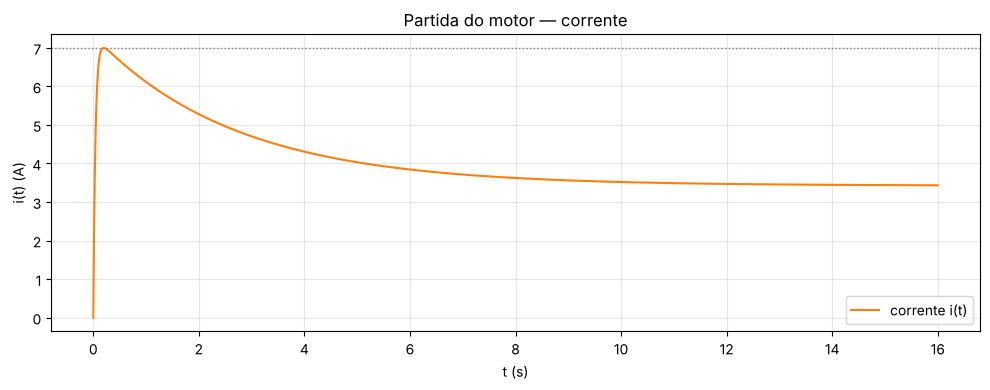

In [9]:
# Validação — Etapa 3 (não modifique esta célula)
import numpy as np

assert ("ts3" in dir() and "Ys3" in dir() and "pico_corrente" in dir() and "t_pico" in dir()
        and "omega_ss_teorico" in dir() and "tempo_95" in dir()), \
    "Defina ts3, Ys3, pico_corrente, t_pico, omega_ss_teorico e tempo_95"

ts3_arr = np.array(ts3, dtype=float)
Ys3_arr = np.array(Ys3, dtype=float)
assert Ys3_arr.shape[1] == 2, "Ys3 deveria ter 2 colunas: [i, omega]"
assert np.allclose(Ys3_arr[0], [0.0, 0.0], atol=1e-6), "A simulação deveria começar em [0, 0]"

assert np.isclose(pico_corrente, 7.00, atol=0.3), f"pico_corrente deveria ser aproximadamente 7.0 A (encontrado {pico_corrente:.3f})"
assert np.isclose(t_pico, 0.20, atol=0.1), f"t_pico deveria ser próximo de 0.2 s (encontrado {t_pico:.3f})"
assert np.isclose(omega_ss_teorico, 156.95, atol=1.5), f"omega_ss_teorico deveria ser aproximadamente 157 rad/s (encontrado {omega_ss_teorico:.2f})"
assert np.isclose(tempo_95, 8.09, atol=0.6), f"tempo_95 deveria ser aproximadamente 8.1 s (encontrado {tempo_95:.3f})"

print("Etapa 3 OK!")
print(f"  pico_corrente = {pico_corrente:.3f} A  em t = {t_pico:.3f} s")
print(f"  omega_ss_teorico = {omega_ss_teorico:.2f} rad/s   tempo_95 = {tempo_95:.3f} s")

plt.figure(figsize=(10, 4))
plt.plot(ts3_arr, Ys3_arr[:, 0], color="tab:orange", label="corrente i(t)")
plt.axhline(pico_corrente, color="gray", ls=":", lw=1)
plt.xlabel("t (s)")
plt.ylabel("i(t) (A)")
plt.title("Partida do motor — corrente")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

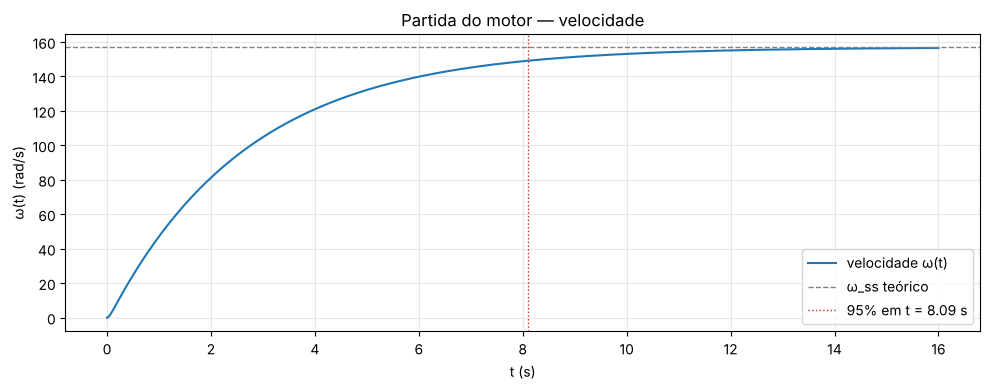

In [10]:
# Gráfico — Etapa 3: velocidade angular
plt.figure(figsize=(10, 4))
plt.plot(ts3, Ys3[:, 1], color="tab:blue", label="velocidade ω(t)")
plt.axhline(omega_ss_teorico, color="gray", ls="--", lw=1, label="ω_ss teórico")
plt.axvline(tempo_95, color="tab:red", ls=":", lw=1, label=f"95% em t = {tempo_95:.2f} s")
plt.xlabel("t (s)")
plt.ylabel("ω(t) (rad/s)")
plt.title("Partida do motor — velocidade")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## Pergunta

Comparando com o motor visto na aula (R ≈ 3.17 Ω, V = 24 V, pico de corrente ≈ 7.1 A), este
motor tem R maior e V maior — e ainda assim o pico de corrente ficou parecido. Por quê?

**Minha resposta:**

O pico de corrente na partida é dominado pela razão V/R: com ω = 0 não há força contraeletromotriz, então a corrente só é limitada por V/R. Aqui 36/4,99 ≈ 7,2 A; no motor da aula, 24/3,17 ≈ 7,6 A. Como R (×1,57) e V (×1,5) aumentaram em proporção parecida, a razão V/R quase não mudou e o pico ficou parecido. O pico real fica um pouco abaixo de V/R (≈ 7,0 A e ≈ 7,1 A) porque o rotor já começa a girar e gera força contraeletromotriz (Ke·ω) antes de a corrente atingir o máximo.

---
## Etapa 4 (Aprofundamento, opcional) — Degrau de Carga

Com o motor já em regime (t = 12 s), uma carga de $T_{carga} = 0.15$ N·m é aplicada
repentinamente.

## Roteiro

1. Adapte `F_motor` para que `T_carga` dependa do tempo: 0 antes de $t=12$ s, 0.15 N·m a
   partir daí.
2. Resolva com `rk4_sistema` até $t=24$ s, mesmo $h=0.002$ s. Guarde em `ts4` e `Ys4`.
3. Observe a nova velocidade de regime após o degrau.

In [11]:
# Etapa 4 — Resolução (opcional)
def F_degrau(t, Y, Vt):
    Tl = 0.0 if t < 12.0 else 0.15
    return F_motor(t, Y, Vt, Tl)

h = 0.002
t_eval4 = np.arange(0.0, 24.0 + h/2, h)
sol4 = solve_ivp(F_degrau, [0.0, 24.0], [0.0, 0.0], t_eval=t_eval4,
                 max_step=h, rtol=1e-9, atol=1e-12, args=(V_nom,))
ts4, Ys4 = sol4.t, sol4.y.T

Etapa 4 (Aprofundamento) OK! Velocidade final após o degrau: 130.15 rad/s


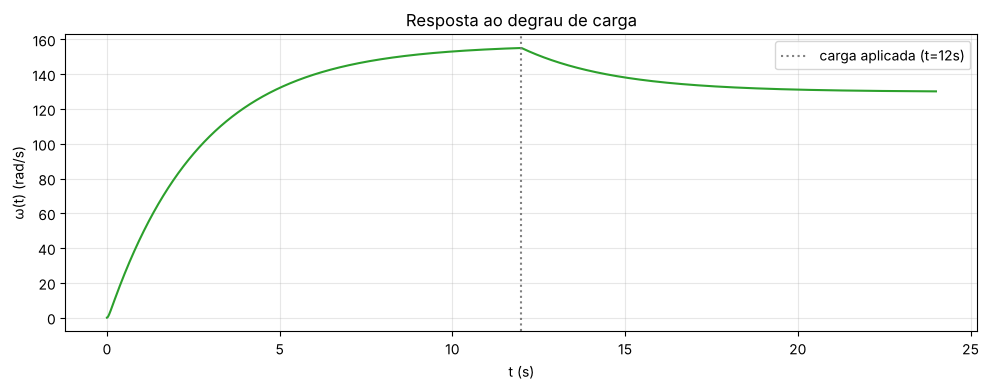

In [12]:
# Validação — Etapa 4 (não modifique esta célula)
import numpy as np

if "ts4" in dir() and "Ys4" in dir():
    Ys4_arr = np.array(Ys4, dtype=float)
    omega_final = Ys4_arr[-1, 1]
    assert np.isclose(omega_final, 130.15, atol=1.5), \
        f"A velocidade final após o degrau deveria ser aproximadamente 130 rad/s (encontrado {omega_final:.2f})"
    print(f"Etapa 4 (Aprofundamento) OK! Velocidade final após o degrau: {omega_final:.2f} rad/s")

    plt.figure(figsize=(10, 4))
    plt.plot(np.array(ts4, dtype=float), Ys4_arr[:, 1], color="tab:green")
    plt.axvline(12.0, color="gray", ls=":", label="carga aplicada (t=12s)")
    plt.xlabel("t (s)")
    plt.ylabel("ω(t) (rad/s)")
    plt.title("Resposta ao degrau de carga")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("Etapa 4 (Aprofundamento) não resolvida — tudo bem, é opcional.")

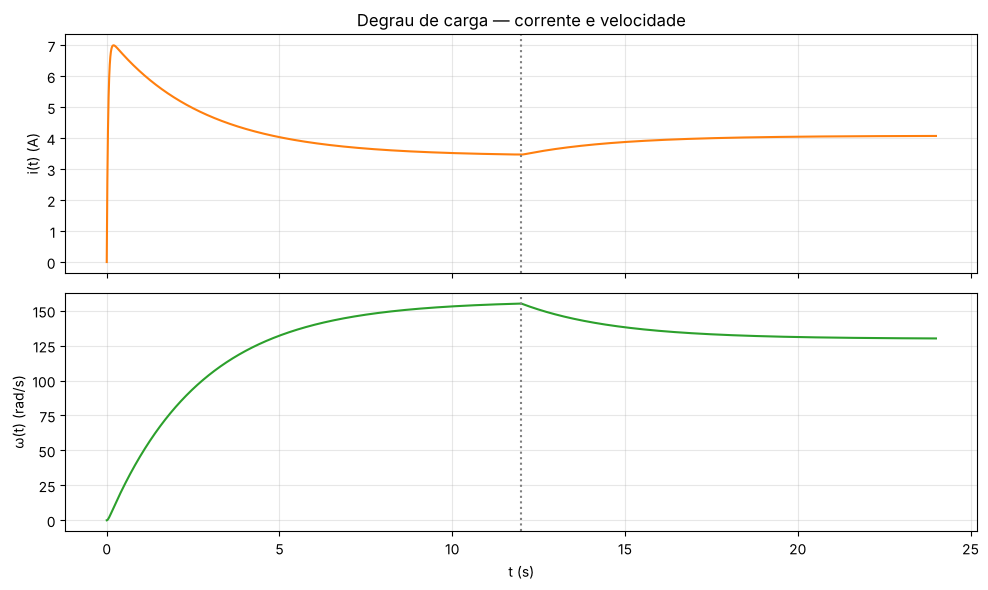

In [13]:
# Gráfico — Etapa 4: corrente e velocidade
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].plot(ts4, Ys4[:, 0], color="tab:orange")
ax[0].axvline(12.0, color="gray", ls=":")
ax[0].set_ylabel("i(t) (A)")
ax[0].set_title("Degrau de carga — corrente e velocidade")
ax[1].plot(ts4, Ys4[:, 1], color="tab:green")
ax[1].axvline(12.0, color="gray", ls=":")
ax[1].set_ylabel("ω(t) (rad/s)")
ax[1].set_xlabel("t (s)")
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

---
### Não esqueça

```bash
git add atividade_miniprojeto_motor_extensao.ipynb
git commit -m "Extensao do mini-projeto: motor CC (calibracao + simulacao)"
git push
```